# Import Library & Dataset

In [3]:
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [4]:
import string, os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from wordcloud import WordCloud

from nltk.tag import pos_tag
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import SnowballStemmer, WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [5]:
import kagglehub
from pathlib import Path

# Mental Health Corpus (27,977 posts), downloaded once to the kagglehub cache
MH_DIR = Path(kagglehub.dataset_download("reihanenamdari/mental-health-corpus"))
df = pd.read_csv(MH_DIR / "mental_health.csv")

# Exploratory Data Analysis

Lihat data dalam dataset

In [6]:
print(df)

                                                    text  label
0      dear american teens question dutch person hear...      0
1      nothing look forward lifei dont many reasons k...      1
2      music recommendations im looking expand playli...      0
3      im done trying feel betterthe reason im still ...      1
4      worried  year old girl subject domestic physic...      1
...                                                  ...    ...
27972  posting everyday people stop caring  religion ...      0
27973  okay definetly need hear guys opinion ive pret...      0
27974  cant get dog think ill kill myselfthe last thi...      1
27975  whats point princess bridei really think like ...      1
27976  got nudes person might might know snapchat do ...      0

[27977 rows x 2 columns]


Lihat shape row dan column dalam dataset

In [7]:
print(df.shape)

(27977, 2)


Lihat informasi dari df, berisikan jumlah row, jumlah column, data type, dan non-null count

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27977 entries, 0 to 27976
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    27977 non-null  object
 1   label   27977 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 437.3+ KB


Cek missing value



In [9]:
print(df.isnull().sum())

text     0
label    0
dtype: int64


Lihat jumlah data label 0 dan 1

In [10]:
print(df.label.value_counts())

label
0    14139
1    13838
Name: count, dtype: int64


Diagram untuk distribusi label (pie chart dan bar chart)

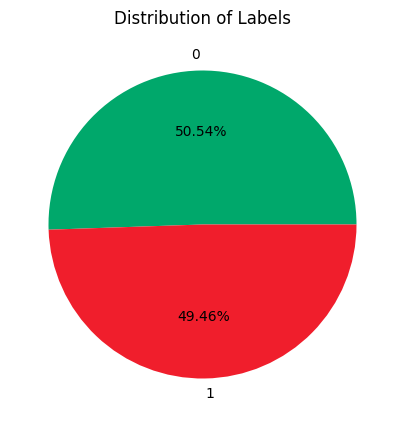

In [12]:
label_counts = df['label'].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(label_counts, labels=label_counts.index, autopct='%1.2f%%', colors=['#00A86B', '#F01E2C'])
plt.title('Distribution of Labels')
plt.show()

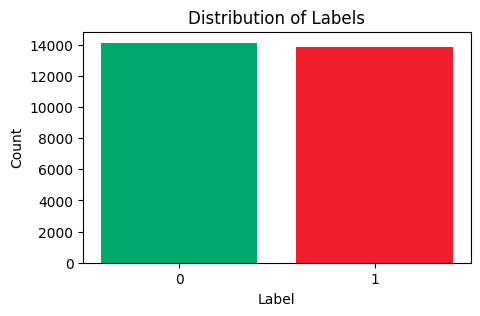

In [15]:
plt.figure(figsize=(5, 3))
plt.bar(label_counts.index, label_counts.values, color=['#00A86B', '#F01E2C'])
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Distribution of Labels')
plt.xticks(label_counts.index)
plt.show()

Lihat kata-kata yang sering muncul dengan word cloud

In [16]:
def plot_wordcloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(5, 3))
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.title(title)
    plt.show()

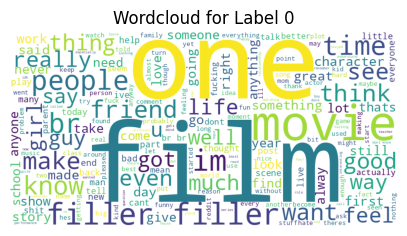

In [17]:
text_label_0 = " ".join(df[df['label'] == 0]['text'].astype(str))
plot_wordcloud(text_label_0, "Wordcloud for Label 0")

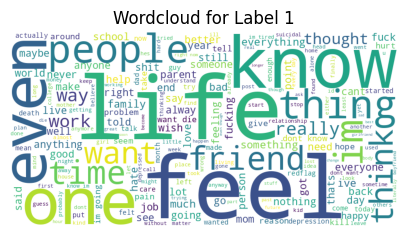

In [18]:
text_label_1 = " ".join(df[df['label'] == 1]['text'].astype(str))
plot_wordcloud(text_label_1, "Wordcloud for Label 1")

 Lihat frekuensi kata yang paling banyak muncul berdasarkan label

In [19]:
def count_words(df):
    word_counts_label_0 = {}
    word_counts_label_1 = {}

    for index, row in df.iterrows():
        text = row['text']
        label = row['label']
        words = word_tokenize(text)

        for word in words:
            word = word.lower()
            if label == 0:
                word_counts_label_0[word] = word_counts_label_0.get(word, 0) + 1
            elif label == 1:
                word_counts_label_1[word] = word_counts_label_1.get(word, 0) + 1

    df_label_0 = pd.DataFrame({'Word': list(word_counts_label_0.keys()), 'Count': list(word_counts_label_0.values())})
    df_label_1 = pd.DataFrame({'Word': list(word_counts_label_1.keys()), 'Count': list(word_counts_label_1.values())})

    df_label_0 = df_label_0.sort_values(by='Count', ascending=False)
    df_label_1 = df_label_1.sort_values(by='Count', ascending=False)

    return df_label_0, df_label_1

In [20]:
df_label_0, df_label_1 = count_words(df)

print("Top Word List for Label 0:\n", df_label_0)

Top Word List for Label 0:
                  Word  Count
18               like   6780
23                 im   6676
206                br   5608
110               one   4548
182              film   3880
...               ...    ...
48987        newsroom      1
48988          chezit      1
48989        chezthem      1
48990  motherdaughter      1
48992           romps      1

[49018 rows x 2 columns]


In [21]:
print("Top Word List for Label 1:\n", df_label_1)

Top Word List for Label 1:
                 Word  Count
18                im  28044
10              like  15520
15              want  14944
34              life  12669
9               feel  12660
...              ...    ...
42102   individualit      1
42103      testement      1
42104          wolrd      1
42105  oversaturated      1
42106       communal      1

[42126 rows x 2 columns]


Kesimpulan EDA:
1. Dataset memiliki 27.977 baris dan 2 kolom (text dan label)
2. Tidak terdapat missing values di dalam dataset
3. Distribusi kelas label 0 dan 1 cukup seimbang
4. Label 0 cenderung memiliki kata-kata yang lebih beragam dan berhubungan dengan topik spesifik, seperti film
5. Label 1 lebih banyak mengandung kata-kata yang terkait dengan emosi

# Preprocessing

- wordnet lemma untuk buat kata jadi kata dasar
- simpan punctuation dari library string
- snowballstemmer untuk memotong kata
- stopwords dari library NLTK

In [23]:
wnl = WordNetLemmatizer()
punctuation_list = string.punctuation
stemming = SnowballStemmer("english")
eng_stopwords = stopwords.words("english")
clean_stopwords = {"".join(char for char in word if char not in string.punctuation) for word in eng_stopwords}

In [24]:
print(eng_stopwords)
print(clean_stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

function preprocessing

In [27]:
def remove_stopwords(word_list):
  return [word for word in word_list if word not in eng_stopwords]

def remove_clean_stopwords(word_list):
  return [word for word in word_list if word not in clean_stopwords]

def remove_punctuation_numbers(word_list):
  return [word for word in word_list if word.isalpha()]

def stemming_word(word_list):
  return [stemming.stem(word) for word in word_list]

def get_tag(tag):
  if tag in ('JJ', 'JJR', 'JJS'):
    return 'a'
  elif tag in ('NN', 'NNS', 'NNP', 'NNPS'):
    return 'n'
  elif tag in ('VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'):
    return 'v'
  elif tag in ('RB', 'RBR', 'RBS'):
    return 'r'
  else:
    return None

def lemmatizing_word(word_list):
  lemma = []
  tagging = pos_tag(word_list)

  for word, tag in tagging:
    label = get_tag(tag.upper())

    if label != None:
      lemma.append(wnl.lemmatize(word, label))
    else:
      lemma.append(wnl.lemmatize(word))

  return lemma

In [28]:
def preprocess_text(text):
  words = word_tokenize(text.lower())
  words = remove_stopwords(words)
  words = remove_clean_stopwords(words)
  words = remove_punctuation_numbers(words)
  words = stemming_word(words)
  words = lemmatizing_word(words)

  return " ".join(words)

Langkah-langkah preprocess:
1. Mengubah kalimat menjadi token
2. Menghapus stopwords
3. Menghapus punctuation dan angka
4. Melakukan stemming
5. Melakukan lemmatization. Sebelum lemma, kata di POS Tag agar bentuk katanya lebih akurat saat diproses oleh WordNet Lemma. Lalu, POS tag itu ditranslate menggunakan get_tag(). Jika POS tag tidak dikenali, kata tetap dilemmatize dalam bentuk default

preprocess textnya

In [29]:
clean_texts = []

for text in df["text"].astype(str):
  clean_texts.append(preprocess_text(text))

df["clean_text"] = clean_texts

In [30]:
print(df[["text", "clean_text"]])

                                                    text  \
0      dear american teens question dutch person hear...   
1      nothing look forward lifei dont many reasons k...   
2      music recommendations im looking expand playli...   
3      im done trying feel betterthe reason im still ...   
4      worried  year old girl subject domestic physic...   
...                                                  ...   
27972  posting everyday people stop caring  religion ...   
27973  okay definetly need hear guys opinion ive pret...   
27974  cant get dog think ill kill myselfthe last thi...   
27975  whats point princess bridei really think like ...   
27976  got nudes person might might know snapchat do ...   

                                              clean_text  
0      dear american teen question dutch person hear ...  
1      noth look forward lifei mani reason keep go fe...  
2      music recommend look expand playlist usual gen...  
3      do tri feel betterth reason still al

Kata-kata yang sering muncul menggunakan word cloud setelah dataset di preprocess

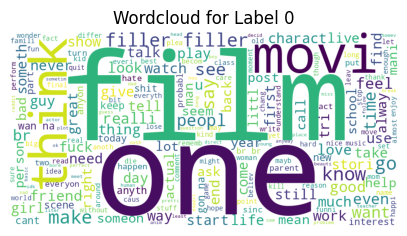

In [31]:
clean_text_label_0 = " ".join(df[df['label'] == 0]['clean_text'].astype(str))
plot_wordcloud(clean_text_label_0, "Wordcloud for Label 0")

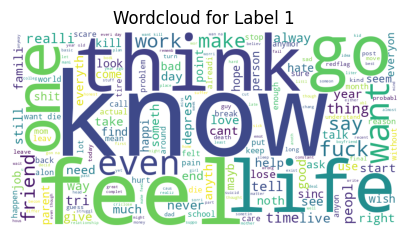

In [32]:
clean_text_label_1 = " ".join(df[df['label'] == 1]['clean_text'].astype(str))
plot_wordcloud(clean_text_label_1, "Wordcloud for Label 1")

Cek frekuensi kata dalam df setelah di preprocess

In [33]:
def count_clean_words(df):
    word_counts_label_0 = {}
    word_counts_label_1 = {}

    for index, row in df.iterrows():
        text = row['clean_text']
        label = row['label']
        words = word_tokenize(text)

        for word in words:
            word = word.lower()
            if label == 0:
                word_counts_label_0[word] = word_counts_label_0.get(word, 0) + 1
            elif label == 1:
                word_counts_label_1[word] = word_counts_label_1.get(word, 0) + 1

    df_label_0 = pd.DataFrame({'Word': list(word_counts_label_0.keys()), 'Count': list(word_counts_label_0.values())})
    df_label_1 = pd.DataFrame({'Word': list(word_counts_label_1.keys()), 'Count': list(word_counts_label_1.values())})

    df_label_0 = df_label_0.sort_values(by='Count', ascending=False)
    df_label_1 = df_label_1.sort_values(by='Count', ascending=False)

    return df_label_0, df_label_1

In [34]:
df_label_0, df_label_1 = count_clean_words(df)

print("Top Word List for Label 0:\n", df_label_0)

Top Word List for Label 0:
            Word  Count
18         like   7453
8           get   6329
177          br   5608
156        film   4849
96          one   4800
...         ...    ...
20465  martywho      1
20462   dankmem      1
20459   felinni      1
20458    pendul      1
20453      defo      1

[35321 rows x 2 columns]


In [35]:
print("Top Word List for Label 1:\n", df_label_1)

Top Word List for Label 1:
             Word  Count
13          want  18580
8           feel  17630
56           get  17507
9           like  16248
7             go  15733
...          ...    ...
30492   longlook      1
30440     herask      1
30441  selfident      1
30442   reappear      1
30443    leftmad      1

[30536 rows x 2 columns]


# Data Splitting

Data splitting:
1. Memisahkan kolom fitur (X) dan kolom label (y).
2. X: Kolom "clean_text" yang berisi teks yang telah dipreprocess
3. y: Kolom "label" yang berisi label klasifikasi
4. Train-test split pertama untuk membagi 80% data training dan 20% data testing
5. Train-test split kedua untuk membagi lagi data training. Jadi pembagiannya menjadi 70:10:20


In [36]:
X = df["clean_text"]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42, stratify=y_train)

In [37]:
print(f"Train data size: {len(X_train)} ({len(X_train)/len(df)*100:.2f}%)")
print(f"Validation data size: {len(X_val)} ({len(X_val)/len(df)*100:.2f}%)")
print(f"Test data size: {len(X_test)} ({len(X_test)/len(df)*100:.2f}%)")

Train data size: 19583 (70.00%)
Validation data size: 2798 (10.00%)
Test data size: 5596 (20.00%)


* Data training (70%) digunakan untuk melatih model
* Data validation (10%) digunakan untuk mengukur kinerja model selama pelatihan (untuk tuning hyperparameter)
* Data testing (20%) digunakan untuk menguji model yang sudah dilatih setelah proses pelatihan selesai

# TF-IDF Vectorization

TF-IDF bekerja dengan memberikan bobot numerik pada setiap kata berdasarkan seberapa sering kata tersebut muncul dalam dokumen dan seberapa jarang kata tersebut muncul di dalam korpus. Pendekatan ini akan lebih bagus dibandingkan menggunakan word2vec untuk model tradisional seperti LR atau NB karena menghasilkan fitur yang terpisah dan langusng merepresentasikan pentingknya kata dalam konteks dokumen.

Menghitung jumlah kata unik yang ada di dalam dataset X_train.

In [38]:
vectorizer = CountVectorizer()
vectorizer.fit(X_train)
print(len(vectorizer.get_feature_names_out()))

43331


In [39]:
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

Langkah-langkah TF-IDF Vectorization:
* Mengubah teks menjadi representasi numerik dengan mempertimbangkan frekuensi kata dalam dokumen dan seberapa unik kata tersebut di seluruh dokumen. Max_features yang digunakan adalah 5000 untuk menghindari dimensi yang terlalu besar, mencegah overfitting, dan meningkatkan efisiensi komputasi. Fitur yang diambil adalah kata-kata yang paling sering muncul, sehingga tetap representatif terhadap dataset
* Memproses teks X_train, menghitung skor TF-IDF, dan mengubahnya menjadi matriks numerik
* Mengubah data validasi (X_val) dan data testing (X_test) menggunakan model yang sudah dilatih dari X_train

# Model 1: Voting Classifier (SVM, Naive Bayes, XGBoost)

In [40]:
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import VotingClassifier

from xgboost import XGBClassifier

In [41]:
svm_model = SVC(probability=True, kernel='linear', random_state=42)
nb_model = MultinomialNB()
xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)

svm_model.fit(X_train_tfidf, y_train)
nb_model.fit(X_train_tfidf, y_train)
xgb_model.fit(X_train_tfidf, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

In [42]:
voting_clf = VotingClassifier(
    estimators=[('svm', svm_model), ('nb', nb_model), ('xgb', xgb_model)],
    voting='soft'
)

voting_clf.fit(X_train_tfidf, y_train)

VotingClassifier(estimators=[('svm',
                              SVC(kernel='linear', probability=True,
                                  random_state=42)),
                             ('nb', MultinomialNB()),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_types=None...
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None,
                                            random_state=42, ...))],
                 voting='soft')

## Evaluation

In [43]:
y_train_pred = voting_clf.predict(X_train_tfidf)
print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Train F1-Score:", f1_score(y_train, y_train_pred, average='weighted'))
print(classification_report(y_train, y_train_pred))

Train Accuracy: 0.9531226063422357
Train F1-Score: 0.9531234740497333
              precision    recall  f1-score   support

           0       0.96      0.95      0.95      9897
           1       0.95      0.95      0.95      9686

    accuracy                           0.95     19583
   macro avg       0.95      0.95      0.95     19583
weighted avg       0.95      0.95      0.95     19583



In [44]:
y_val_pred = voting_clf.predict(X_val_tfidf)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation F1-Score:", f1_score(y_val, y_val_pred, average='weighted'))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.9249463902787706
Validation F1-Score: 0.9249415584149139
              precision    recall  f1-score   support

           0       0.94      0.91      0.92      1414
           1       0.91      0.94      0.93      1384

    accuracy                           0.92      2798
   macro avg       0.93      0.93      0.92      2798
weighted avg       0.93      0.92      0.92      2798



In [45]:
y_test_pred = voting_clf.predict(X_test_tfidf)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test F1-Score:", f1_score(y_test, y_test_pred, average='weighted'))
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.9206576125804146
Test F1-Score: 0.9206598523920317
              precision    recall  f1-score   support

           0       0.93      0.92      0.92      2828
           1       0.91      0.93      0.92      2768

    accuracy                           0.92      5596
   macro avg       0.92      0.92      0.92      5596
weighted avg       0.92      0.92      0.92      5596



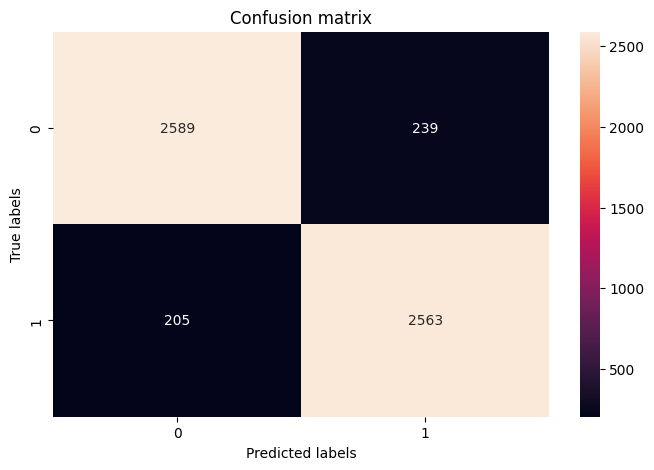

In [46]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.title("Confusion matrix")
plt.show()

# Model 2: Support Vector Machine

In [47]:
svm_model = SVC(probability=True, kernel='linear', random_state=42)
svm_model.fit(X_train_tfidf, y_train)

SVC(kernel='linear', probability=True, random_state=42)

## Evaluation

In [48]:
y_train_pred = svm_model.predict(X_train_tfidf)
print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Train F1-Score:", f1_score(y_train, y_train_pred, average='weighted'))
print(classification_report(y_train, y_train_pred))

Train Accuracy: 0.9493438186181893
Train F1-Score: 0.9493403422231906
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      9897
           1       0.95      0.94      0.95      9686

    accuracy                           0.95     19583
   macro avg       0.95      0.95      0.95     19583
weighted avg       0.95      0.95      0.95     19583



In [49]:
y_val_pred = svm_model.predict(X_val_tfidf)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation F1-Score:", f1_score(y_val, y_val_pred, average='weighted'))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.9238741958541815
Validation F1-Score: 0.9238698094739407
              precision    recall  f1-score   support

           0       0.92      0.93      0.92      1414
           1       0.93      0.92      0.92      1384

    accuracy                           0.92      2798
   macro avg       0.92      0.92      0.92      2798
weighted avg       0.92      0.92      0.92      2798



In [50]:
y_test_pred = svm_model.predict(X_test_tfidf)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test F1-Score:", f1_score(y_test, y_test_pred, average='weighted'))
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.92012151536812
Test F1-Score: 0.9201094586489451
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      2828
           1       0.93      0.91      0.92      2768

    accuracy                           0.92      5596
   macro avg       0.92      0.92      0.92      5596
weighted avg       0.92      0.92      0.92      5596



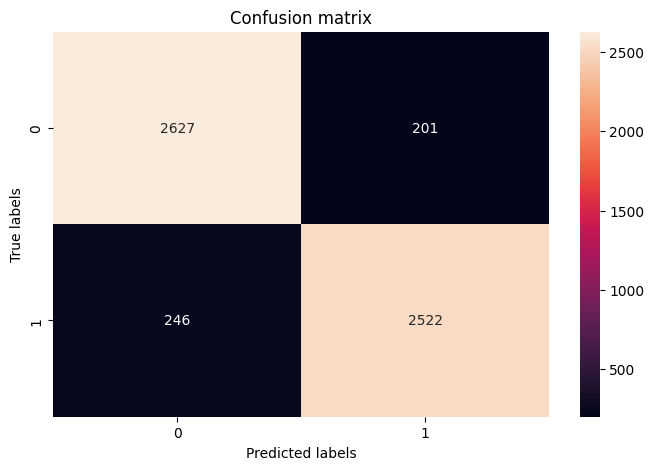

In [51]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.title("Confusion matrix")
plt.show()

# Model 3: Naive Bayes (MultinomialNB)

In [52]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

## Evaluation

In [53]:
y_train_pred = nb_model.predict(X_train_tfidf)
print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Train F1-Score:", f1_score(y_train, y_train_pred, average='weighted'))
print(classification_report(y_train, y_train_pred))

Train Accuracy: 0.903079201348108
Train F1-Score: 0.9027873265854971
              precision    recall  f1-score   support

           0       0.96      0.84      0.90      9897
           1       0.86      0.96      0.91      9686

    accuracy                           0.90     19583
   macro avg       0.91      0.90      0.90     19583
weighted avg       0.91      0.90      0.90     19583



In [54]:
y_val_pred = nb_model.predict(X_val_tfidf)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation F1-Score:", f1_score(y_val, y_val_pred, average='weighted'))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.8902787705503932
Validation F1-Score: 0.8896960138406098
              precision    recall  f1-score   support

           0       0.96      0.81      0.88      1414
           1       0.84      0.97      0.90      1384

    accuracy                           0.89      2798
   macro avg       0.90      0.89      0.89      2798
weighted avg       0.90      0.89      0.89      2798



In [55]:
y_test_pred = nb_model.predict(X_test_tfidf)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test F1-Score:", f1_score(y_test, y_test_pred, average='weighted'))
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.8906361686919227
Test F1-Score: 0.8901542257618009
              precision    recall  f1-score   support

           0       0.96      0.82      0.88      2828
           1       0.84      0.96      0.90      2768

    accuracy                           0.89      5596
   macro avg       0.90      0.89      0.89      5596
weighted avg       0.90      0.89      0.89      5596



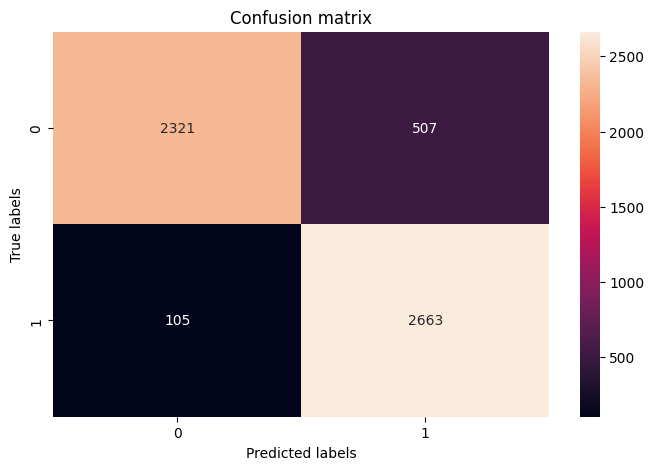

In [56]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.title("Confusion matrix")
plt.show()

# Model 4: XGBoost

In [57]:
xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)
xgb_model.fit(X_train_tfidf, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

## Evaluation

In [58]:
y_train_pred = xgb_model.predict(X_train_tfidf)
print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Train F1-Score:", f1_score(y_train, y_train_pred, average='weighted'))
print(classification_report(y_train, y_train_pred))

Train Accuracy: 0.9483225246387172
Train F1-Score: 0.9482853424556488
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      9897
           1       0.97      0.93      0.95      9686

    accuracy                           0.95     19583
   macro avg       0.95      0.95      0.95     19583
weighted avg       0.95      0.95      0.95     19583



In [59]:
y_val_pred = xgb_model.predict(X_val_tfidf)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation F1-Score:", f1_score(y_val, y_val_pred, average='weighted'))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.9081486776268763
Validation F1-Score: 0.9081421176186475
              precision    recall  f1-score   support

           0       0.91      0.91      0.91      1414
           1       0.91      0.90      0.91      1384

    accuracy                           0.91      2798
   macro avg       0.91      0.91      0.91      2798
weighted avg       0.91      0.91      0.91      2798



In [60]:
y_test_pred = xgb_model.predict(X_test_tfidf)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test F1-Score:", f1_score(y_test, y_test_pred, average='weighted'))
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.9049320943531094
Test F1-Score: 0.9049006973928923
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      2828
           1       0.92      0.89      0.90      2768

    accuracy                           0.90      5596
   macro avg       0.91      0.90      0.90      5596
weighted avg       0.91      0.90      0.90      5596



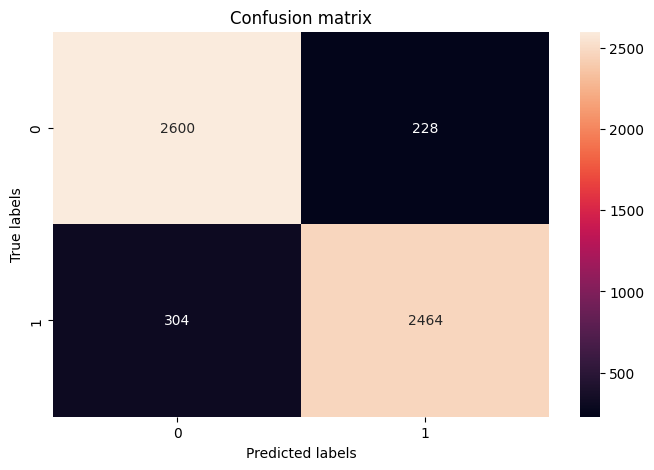

In [61]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.title("Confusion matrix")
plt.show()

# Model 5: Logistic Regression

In [62]:
from sklearn.linear_model import LogisticRegression

In [63]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000, random_state=42)

## Evaluation

In [64]:
y_train_pred = lr_model.predict(X_train_tfidf)
print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Train F1-Score:", f1_score(y_train, y_train_pred, average='weighted'))
print(classification_report(y_train, y_train_pred))

Train Accuracy: 0.936373385078895
Train F1-Score: 0.9363593325748882
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      9897
           1       0.95      0.93      0.93      9686

    accuracy                           0.94     19583
   macro avg       0.94      0.94      0.94     19583
weighted avg       0.94      0.94      0.94     19583



In [65]:
y_val_pred = lr_model.predict(X_val_tfidf)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation F1-Score:", f1_score(y_val, y_val_pred, average='weighted'))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.918155825589707
Validation F1-Score: 0.9181446253805131
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      1414
           1       0.92      0.91      0.92      1384

    accuracy                           0.92      2798
   macro avg       0.92      0.92      0.92      2798
weighted avg       0.92      0.92      0.92      2798



In [66]:
y_test_pred = lr_model.predict(X_test_tfidf)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test F1-Score:", f1_score(y_test, y_test_pred, average='weighted'))
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.9174410293066476
Test F1-Score: 0.9174137635254065
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      2828
           1       0.93      0.90      0.92      2768

    accuracy                           0.92      5596
   macro avg       0.92      0.92      0.92      5596
weighted avg       0.92      0.92      0.92      5596



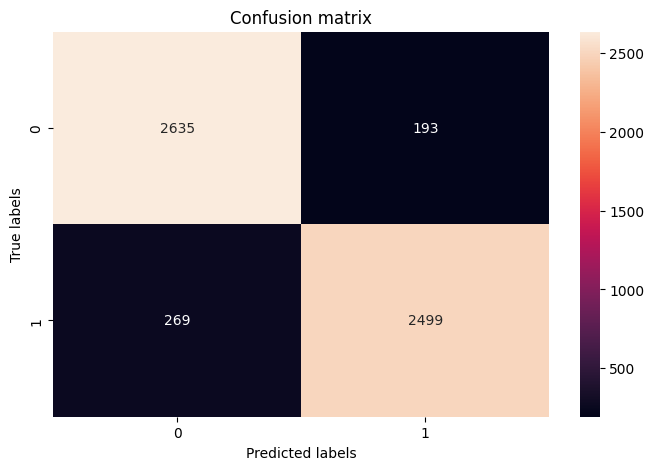

In [67]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.title("Confusion matrix")
plt.show()

# Model 6: Long Short-Term Memory (LSTM)

In [68]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [69]:
X_train_tfidf_3d = np.expand_dims(X_train_tfidf.toarray(), axis=1)
X_val_tfidf_3d = np.expand_dims(X_val_tfidf.toarray(), axis=1)
X_test_tfidf_3d = np.expand_dims(X_test_tfidf.toarray(), axis=1)

print("Shape X_train_tfidf_3d:", X_train_tfidf_3d.shape)

Shape X_train_tfidf_3d: (19583, 1, 5000)


In [70]:
n_features = X_train_tfidf_3d.shape[2]
n_classes = len(np.unique(y_train))

model = Sequential([
    LSTM(64, input_shape=(1, n_features)),
    Dropout(0.5),
    Dense(n_classes, activation='softmax')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [71]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │     1,296,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,296,770 (4.95 MB)

 Trainable params: 1,296,770 (4.95 MB)

 Non-trainable params: 0 (0.00 B)

In [72]:
history = model.fit(
    X_train_tfidf_3d, y_train,
    validation_data=(X_val_tfidf_3d, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8041 - loss: 0.4499 - val_accuracy: 0.9264 - val_loss: 0.2027
Epoch 2/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9368 - loss: 0.1710 - val_accuracy: 0.9271 - val_loss: 0.1988
Epoch 3/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9466 - loss: 0.1478 - val_accuracy: 0.9239 - val_loss: 0.2015
Epoch 4/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9517 - loss: 0.1291 - val_accuracy: 0.9207 - val_loss: 0.2117
Epoch 5/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9581 - loss: 0.1208 - val_accuracy: 0.9164 - val_loss: 0.2273
Epoch 6/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9633 - loss: 0.1104 - val_accuracy: 0.9139 - val_loss: 0.2442
Epoch 7/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9658 - loss: 0.1019 - val_accuracy: 0.9114 - val_loss: 0.2557
Epoch 8/10
612/612 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9684 - loss: 0.0972 - val_accuracy: 

## Evaluation

In [73]:
y_train_pred = np.argmax(model.predict(X_train_tfidf_3d), axis=1)
print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Train F1-Score:", f1_score(y_train, y_train_pred, average='weighted'))
print(classification_report(y_train, y_train_pred))

612/612 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Train Accuracy: 0.9773272736557218
Train F1-Score: 0.9773265746011858
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9897
           1       0.98      0.97      0.98      9686

    accuracy                           0.98     19583
   macro avg       0.98      0.98      0.98     19583
weighted avg       0.98      0.98      0.98     19583



In [74]:
y_val_pred = np.argmax(model.predict(X_val_tfidf_3d), axis=1)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation F1-Score:", f1_score(y_val, y_val_pred, average='weighted'))
print(classification_report(y_val, y_val_pred))

88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Validation Accuracy: 0.9024303073624017
Validation F1-Score: 0.9024326629853984
              precision    recall  f1-score   support

           0       0.91      0.90      0.90      1414
           1       0.90      0.90      0.90      1384

    accuracy                           0.90      2798
   macro avg       0.90      0.90      0.90      2798
weighted avg       0.90      0.90      0.90      2798



In [75]:
y_test_pred = np.argmax(model.predict(X_test_tfidf_3d), axis=1)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test F1-Score:", f1_score(y_test, y_test_pred, average='weighted'))
print(classification_report(y_test, y_test_pred))

175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test Accuracy: 0.907433881343817
Test F1-Score: 0.9074364353289983
              precision    recall  f1-score   support

           0       0.91      0.90      0.91      2828
           1       0.90      0.91      0.91      2768

    accuracy                           0.91      5596
   macro avg       0.91      0.91      0.91      5596
weighted avg       0.91      0.91      0.91      5596



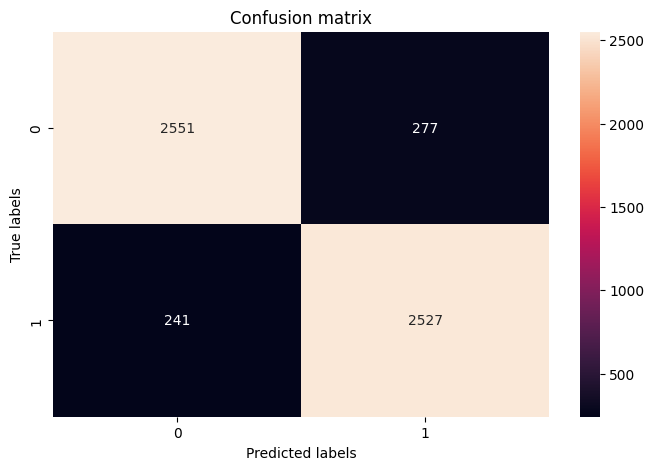

In [76]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.title("Confusion matrix")
plt.show()

# Save Model

Disini model yang di save adalah voting classifier karena model tersebut memberikan peforma terbaik antara training dan testing nya, dimana dia tidak terlalu overfit dengan accuracy kurang lebih 92%

Lalu coba-coba dengan library pickle atau joblib

In [77]:
import pickle

In [78]:
with open('voting_model.pickle', 'wb') as file:
    pickle.dump(voting_clf, file)

In [79]:
import joblib

In [81]:
joblib.dump(voting_clf, 'voting_model.joblib')
joblib.dump(tfidf, 'tfidf_vectorizer.joblib')

['tfidf_vectorizer.joblib']

# Test Load dan Predict Model

Bagian ini untuk tes load model pickle nya

In [80]:
with open('voting_model.pickle', 'rb') as file:
    loaded_model = pickle.load(file)

In [82]:
y_pred = loaded_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred, average='weighted'))

Accuracy: 0.9206576125804146
F1-score: 0.9206598523920317


# Test Sentence

Lalu bagian ini digunakan untuk mengetes kasi sentence ke load model dimana terlihat class: 1 yang berarti merupakan mental health related text

In [83]:
l_model = joblib.load('voting_model.joblib')
tfidf_vectorizer = joblib.load('tfidf_vectorizer.joblib')

In [84]:
print(type(l_model))

<class 'sklearn.ensemble._voting.VotingClassifier'>


In [85]:
new_sentence = "I want to kill my self."
new_sentence_tfidf = tfidf_vectorizer.transform([new_sentence])

predicted_class = l_model.predict(new_sentence_tfidf)
print("Predicted class:", predicted_class[0])

Predicted class: 1
